# Halo model squeezed bispectra
This example illustrates how to use CCL to calculate squeezed bispectra with the halo model which are required for the cross-correlation between halo number counts and 2pt statistics.

In [9]:
import numpy as np
import pyccl as ccl
import pylab as plt
import matplotlib.cm as cm
from scipy.special import erf
%matplotlib inline

## Preliminaries
Generate a cosmology object and a couple of $k$ (comoving wavenumber) and $a$ (scale factor) arrays.

Let us also initialize a series of halo model quantities. We will need:
- A halo mass definition.
- A concentration-mass relation.
- A halo mass function parametrization.
- A halo bias parametrization.
- Halo profiles corresponding to the quantities we want to compute the power spectrum of.


In [10]:
# Cosmology
cosmo = ccl.Cosmology(Omega_c=0.27, Omega_b=0.045, h=0.67, sigma8=0.83, n_s=0.96)

# Wavenumbers and scale factors
k_arr = np.geomspace(1E-4,1E1,256)
a_arr = np.linspace(0.4,1,10)


# We will use a mass definition with Delta = 200 times the matter density
hmd_200m = ccl.halos.MassDef200m

# The Duffy 2008 concentration-mass relation
cM = ccl.halos.ConcentrationDuffy08(mass_def=hmd_200m)

# The Tinker 2008 mass function
nM = ccl.halos.MassFuncTinker08(mass_def=hmd_200m)

# The Tinker 2010 halo bias
bM = ccl.halos.HaloBiasTinker10(mass_def=hmd_200m)

# The NFW profile to characterize the matter density around halos
pM = ccl.halos.HaloProfileNFW(mass_def=hmd_200m, concentration=cM, fourier_analytic=True)


Introduce a galaxy profile based on an HOD and a selection profile for the clusters and its wrapper

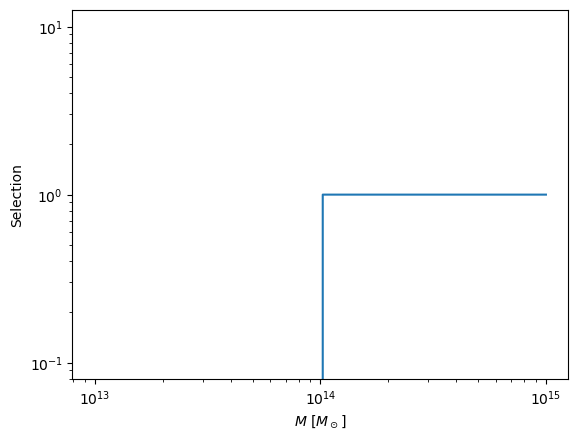

In [11]:
pg = ccl.halos.HaloProfileHOD(mass_def=hmd_200m, concentration=cM)
selection = lambda M, a: (M > 1e14).astype(float)

M_arr = np.logspace(13, 15, 100)

plt.plot(M_arr, selection(M_arr, 1.0))
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$M\,\,[M_\odot]$')
plt.ylabel(r'Selection')

selection_wrapped = ccl.halos.HaloProfileSelection(mass_def=hmd_200m,
    selection=selection)  


Next, we create a halo model calcualtor object which fascilitates the calculations of the bispectra.

In [12]:
hmc = ccl.halos.HMCalculator(
        mass_function=nM,
        halo_bias=bM,
        mass_def=hmd_200m)


Next we create the squeezed contribution from the bispectrum due to nonlinear clustering and the SSC contribution which arises due to the survey response to a long mode.

In [13]:
Bk_squeezed = ccl.halos.halomod_bispectrum_squeezed(cosmo,
        hmc,
        k_arr,
        a_arr,
        selection_wrapped, 
        prof2 = pg)



Bk_squeezed_ssc = ccl.halos.halomod_bispectrum_squeezed_SSC(cosmo,
        hmc,
        k_arr,
        a_arr,
        selection_wrapped,
        prof2 = pg)

Let's plot the two contribution. Note that the two parts project differently, so they should only be summed at the covariance level and their magnitude should not be compared

Text(0.5, 0, '$k\\,\\,[{\\rm Mpc}^{-1}]$')

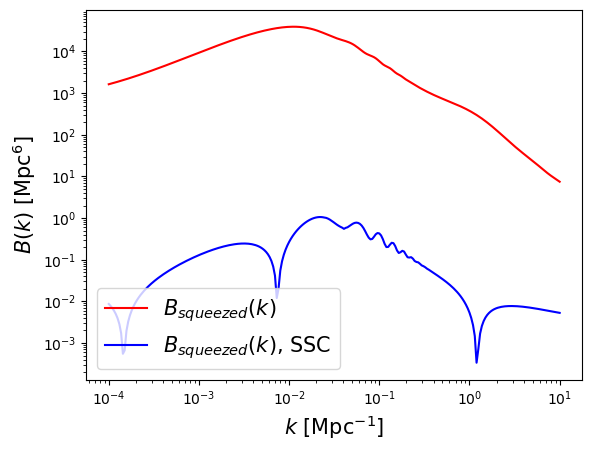

In [14]:
plt.figure()
plt.plot(k_arr, Bk_squeezed[-1], 'r-', label='$B_{squeezed}(k)$')
plt.plot(k_arr, np.abs(Bk_squeezed_ssc[-1]), 'b-', label='$B_{squeezed}(k)$, SSC')
plt.xscale('log')
plt.yscale('log')
plt.legend(loc='lower left', fontsize=15)
plt.ylabel(r'$B(k)\,\,[{\rm Mpc}^6]$', fontsize=15)
plt.xlabel(r'$k\,\,[{\rm Mpc}^{-1}]$', fontsize=15)

There are also two wrapper which allow to create a Pk2D object

(10, 1220)
[0.4        0.46666667 0.53333333 0.6        0.66666667 0.73333333
 0.8        0.86666667 0.93333333 1.        ]
[-9.90348755 -9.88969654 -9.87590553 ...  6.88017326  6.89396427
  6.90775528]


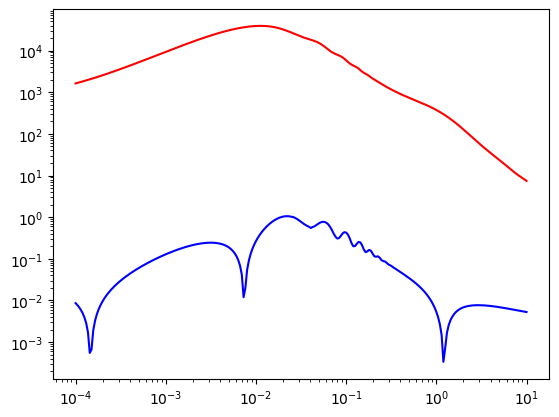

In [23]:
Bk2D_SSC = ccl.halos.halomod_Pk2D_bispectrum_squeezed_SSC(cosmo,hmc, selection_wrapped, prof2=pg, a_arr=a_arr)
Bk2D = ccl.halos.halomod_Pk2D_bispectrum_squeezed(cosmo,hmc, selection_wrapped, prof2=pg, a_arr=a_arr)


plt.loglog(k_arr, np.abs(Bk2D_SSC(k_arr,1)), 'b-', label='SSC')
plt.loglog(k_arr, np.abs(Bk2D(k_arr,1)), 'r-', label='No SSC')

